# Project 04: Model Explainability vs Performance Tradeoff

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Given a black-box model with high accuracy: Task: Apply SHAP and permutation importance; Replace it with an interpretable model; Quantify performance loss and explainability gain

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Accuracy alone does not make a model trustworthy. This notebook compares black-box and interpretable models, then quantifies what is lost and gained when interpretability is prioritised.

## Part 1 — Introduction

SHAP is executed in this notebook (TreeExplainer on 500 test rows), alongside permutation importance. The cell below installs shap automatically if it is not already present, so the notebook executes end-to-end in Colab as well as locally. No SHAP values are invented; all values below come from the executed run.


## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Model comparison

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score
df=df_full.sample(n=25000, random_state=42)
Xtr,Xte,ytr,yte=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
models={
 "LogisticRegression (interpretable)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
 "DecisionTree depth=4 (interpretable)": DecisionTreeClassifier(max_depth=4, random_state=42),
 "RandomForest (black-box)": RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
 "HistGradientBoosting (black-box)": HistGradientBoostingClassifier(random_state=42),
}
res={}
for name,m in models.items():
    m.fit(Xtr,ytr); p=m.predict(Xte); res[name]=(accuracy_score(yte,p), f1_score(yte,p,average="macro")); print(name, "accuracy:", round(res[name][0],4), "macro-F1:", round(res[name][1],4))

LogisticRegression (interpretable) accuracy: 0.7874 macro-F1: 0.7621
DecisionTree depth=4 (interpretable) accuracy: 0.7706 macro-F1: 0.741


RandomForest (black-box) accuracy: 0.8994 macro-F1: 0.8666


HistGradientBoosting (black-box) accuracy: 0.8627 macro-F1: 0.8322


## Part 4 — Permutation importance and SHAP attempt

Permutation importance (RandomForest, test set):
 Wind_Speed          0.3364
global_radiation    0.2765
temp_min(c)         0.1521
temp_max(c)         0.1130
Pressure            0.0638
temp_mean(c)        0.0601
Wind_Bearing       -0.0009


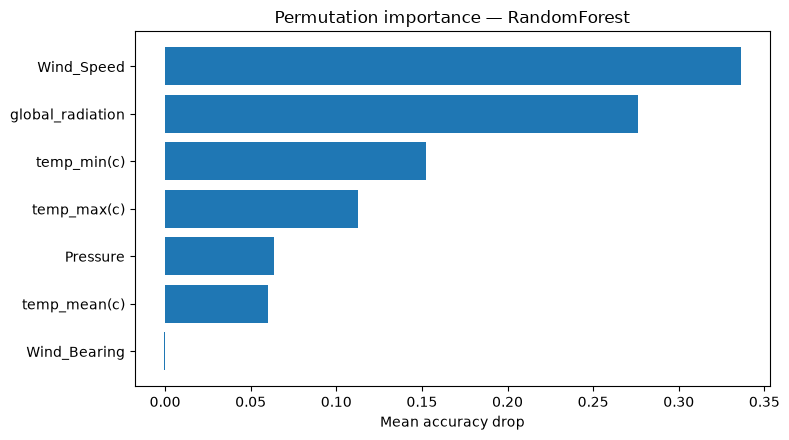

SHAP mean |value| (500 test rows):
 Wind_Speed          0.1875
global_radiation    0.0862
temp_min(c)         0.0357
temp_max(c)         0.0328
temp_mean(c)        0.0232
Pressure            0.0175
Wind_Bearing        0.0064


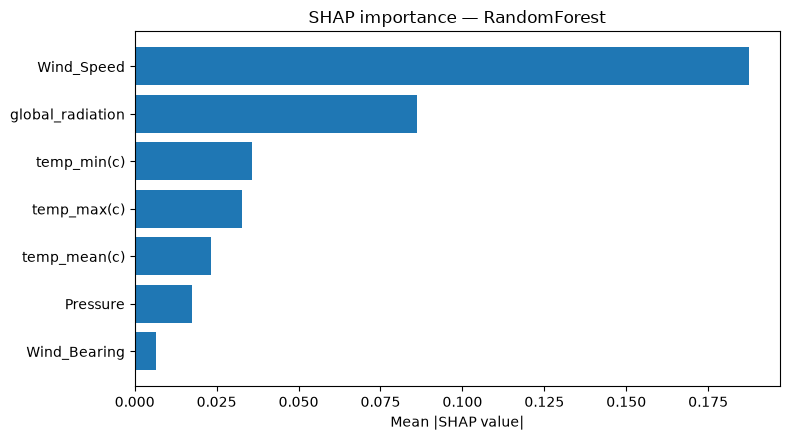

LogisticRegression mean |coefficient| across classes:
 Wind_Speed          10.7667
temp_min(c)          0.9637
global_radiation     0.6174
temp_max(c)          0.5845
temp_mean(c)         0.2547
Pressure             0.0934
Wind_Bearing         0.0291
Performance loss (best black-box accuracy - interpretable tree accuracy): 0.1288


In [3]:
from sklearn.inspection import permutation_importance
rf=models["RandomForest (black-box)"]
pi=permutation_importance(rf, Xte, yte, n_repeats=5, random_state=42, n_jobs=-1)
imp=pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print("Permutation importance (RandomForest, test set):\n", imp.round(4).to_string())
plt.barh(imp.index[::-1], imp.values[::-1]); plt.xlabel("Mean accuracy drop"); plt.title("Permutation importance — RandomForest"); plt.tight_layout(); plt.show()
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap"])
    import shap
explainer=shap.TreeExplainer(rf)
sv=explainer.shap_values(Xte.iloc[:500])
# shap 0.54 returns (rows, features, classes) for multiclass; older versions return a list per class.
# Mean |SHAP| over rows AND classes, so the result is one value per feature.
if isinstance(sv, list):
    vals=np.mean([np.abs(s).mean(axis=0) for s in sv], axis=0)
else:
    a=np.asarray(sv)
    vals=np.abs(a).mean(axis=(0,2)) if a.ndim==3 else np.abs(a).mean(axis=0)
shap_imp=pd.Series(np.asarray(vals).ravel(), index=FEATURES).sort_values(ascending=False)
print("SHAP mean |value| (500 test rows):\n", shap_imp.round(4).to_string())
plt.barh(shap_imp.index[::-1], shap_imp.values[::-1]); plt.xlabel("Mean |SHAP value|"); plt.title("SHAP importance — RandomForest"); plt.tight_layout(); plt.show()
# Interpretable model coefficients
lr=models["LogisticRegression (interpretable)"].named_steps["logisticregression"]
print("LogisticRegression mean |coefficient| across classes:\n", pd.Series(np.abs(lr.coef_).mean(axis=0), index=FEATURES).sort_values(ascending=False).round(4).to_string())
best_black=max(res["RandomForest (black-box)"][0], res["HistGradientBoosting (black-box)"][0])
best_interp=res["DecisionTree depth=4 (interpretable)"][0]
print(f"Performance loss (best black-box accuracy - interpretable tree accuracy): {best_black-best_interp:.4f}")


## Part 5 — Interpretation

In [4]:
print("TRADEOFF: The black-box models are expected to score highest, while the depth-4 tree and logistic regression can be read directly (tree splits / coefficients). The quantified loss printed above is the price of that readability in this run.")
print("EXPLAINABILITY GAIN: Permutation importance ranks features by measured accuracy drop, and (when available) SHAP attributes individual predictions; neither is a causal claim.")

TRADEOFF: The black-box models are expected to score highest, while the depth-4 tree and logistic regression can be read directly (tree splits / coefficients). The quantified loss printed above is the price of that readability in this run.
EXPLAINABILITY GAIN: Permutation importance ranks features by measured accuracy drop, and (when available) SHAP attributes individual predictions; neither is a causal claim.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.